# 06 Hybride model: trainen, vergelijken en evalueren

**Workshops:** LU2 `04_PT and model evaluation` (train/test split, metrics) en vorig jaar `04 Decision Trees`,
`05 Random forest` en `06 Neural Network`.

We maken een **hybride model**: voor elk paar (student, materiaal) berekenen we kenmerken uit het profiel, de inhoud en
het gedrag van andere studenten. Een classificatiemodel leert welke combinatie leidt tot een positieve interactie
(gelezen, geliket of opgeslagen). De voorspelde kans is de score waarop we de catalogus sorteren.

In [1]:
import sys
from pathlib import Path

# Make the project package importable, also without "pip install -e ."
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from leescoach import config

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 200)
config.FIGURES_DIR.mkdir(parents=True, exist_ok=True)

In [2]:
from leescoach.data_cleaning import load_processed
from leescoach.features import FEATURE_COLUMNS, FEATURE_LABELS
from leescoach.hybrid import HybridRecommender
from leescoach.evaluation import temporal_split

materials, students, interactions = load_processed()
train, test = temporal_split(interactions)
print(f"train {len(train)} interacties, test {len(test)} interacties")

train 1500 interacties, test 486 interacties


## 1. Kenmerken per (student, materiaal)

Om **data leakage** te voorkomen berekenen we de collaborative score en de populariteit *out of fold*: voor een groep studenten worden die alleen berekend met de interacties van de andere studenten.

In [3]:
recommender = HybridRecommender()
recommender.fit_components(materials, students, train)
train_frame = recommender.training_frame(students, train)

from leescoach.features import StudentProfile

students_by_id = students.set_index("student_id", drop=False)
test_rows = []
for student_id, own_test in test.groupby("student_id"):
    profile = StudentProfile.from_dataset_row(students_by_id.loc[student_id])
    own_train = train[train["student_id"] == student_id]
    history = dict(zip(own_train["cataloguscode"], own_train["voorkeurscore"]))
    features = recommender.pair_features(profile, history, codes=own_test["cataloguscode"].tolist())
    features["positief"] = own_test["positief"].to_numpy()
    features["student_id"] = student_id
    test_rows.append(features)
test_frame = pd.concat(test_rows)

X_train, y_train = train_frame[FEATURE_COLUMNS], train_frame["positief"]
X_test, y_test = test_frame[FEATURE_COLUMNS], test_frame["positief"]
print(X_train.shape, X_test.shape, f"aandeel positief: {y_train.mean():.2f}")
X_train.describe().T.round(2)

(1500, 14) (486, 14) aandeel positief: 0.30


,count,mean,std,min,25%,50%,75%,max
niveau_verschil,1500.0,-0.06,0.75,-1.50,-0.50,0.00,0.00,1.50
niveau_afstand,1500.0,0.51,0.55,0.00,0.00,0.50,1.00,1.50
type_match,1500.0,0.50,0.43,0.00,0.00,0.50,1.00,1.00
genre_match,1500.0,0.46,0.41,0.00,0.00,0.50,1.00,1.00
interesse_sim,1500.0,0.02,0.04,0.00,0.00,0.00,0.02,0.27
interesse_treffers,1500.0,0.31,0.52,0.00,0.00,0.00,1.00,3.00
geschiedenis_sim,1500.0,0.01,0.02,0.00,0.00,0.00,0.01,0.20
leestijd_ratio_log,1500.0,1.87,1.12,0.04,0.89,1.96,2.75,4.16
leestijd_past,1500.0,0.23,0.42,0.00,0.00,0.00,0.00,1.00
taal_match,1500.0,0.97,0.17,0.00,1.00,1.00,1.00,1.00


## 2. Modellen vergelijken
We vergelijken een simpel model (logistische regressie), een beslisboom, een random forest, gradient boosting en een neuraal netwerk (MLP). Voor modellen die gevoelig zijn voor schaal zetten we een `StandardScaler` in een pipeline.

In [4]:
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score, roc_auc_score
from sklearn.model_selection import GroupKFold, cross_val_score
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier

candidates = {
    "Logistische regressie": make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, class_weight="balanced")),
    "Beslisboom": DecisionTreeClassifier(max_depth=5, min_samples_leaf=10, class_weight="balanced", random_state=config.RANDOM_STATE),
    "Random forest": RandomForestClassifier(n_estimators=400, max_depth=8, min_samples_leaf=5, class_weight="balanced", random_state=config.RANDOM_STATE, n_jobs=-1),
    "Gradient boosting": HistGradientBoostingClassifier(max_depth=4, learning_rate=0.05, max_iter=300, class_weight="balanced", random_state=config.RANDOM_STATE),
    "Neuraal netwerk (MLP)": make_pipeline(StandardScaler(), MLPClassifier(hidden_layer_sizes=(32, 16), alpha=1e-3, max_iter=2000, early_stopping=True, random_state=config.RANDOM_STATE)),
}

rows = []
for name, estimator in candidates.items():
    cv_auc = cross_val_score(estimator, X_train, y_train, groups=train_frame["student_id"], cv=GroupKFold(5), scoring="roc_auc")
    estimator.fit(X_train, y_train)
    probability = estimator.predict_proba(X_test)[:, 1]
    prediction = (probability >= 0.5).astype(int)
    rows.append({
        "model": name,
        "cv_auc (train)": cv_auc.mean(),
        "auc (test)": roc_auc_score(y_test, probability),
        "accuracy": accuracy_score(y_test, prediction),
        "precision": precision_score(y_test, prediction),
        "recall": recall_score(y_test, prediction),
        "f1": f1_score(y_test, prediction),
    })
comparison = pd.DataFrame(rows).set_index("model").round(3)
comparison

,cv_auc (train),auc (test),accuracy,precision,recall,f1
model,,,,,,
Logistische regressie,0.828,0.809,0.714,0.507,0.768,0.611
Beslisboom,0.794,0.785,0.698,0.489,0.761,0.595
Random forest,0.847,0.825,0.722,0.516,0.775,0.620
Gradient boosting,0.829,0.811,0.720,0.516,0.697,0.593
Neuraal netwerk (MLP),0.806,0.796,0.751,0.574,0.570,0.572


**Waarom AUC?** We gebruiken de kans om te sorteren, niet om ja of nee te zeggen. AUC meet precies dat: hoe vaak staat
een materiaal dat de student goed vond hoger dan een materiaal dat hij afwees. 0.5 is gokken, 1.0 is perfect.

**Keuze:** het random forest scoort (bijna) het best, is stabiel en geeft *feature importances* die we aan docenten
kunnen laten zien. Daarom is dat het model in `HybridRecommender`.

## 3. De beslisboom bekijken (uitlegbaarheid)

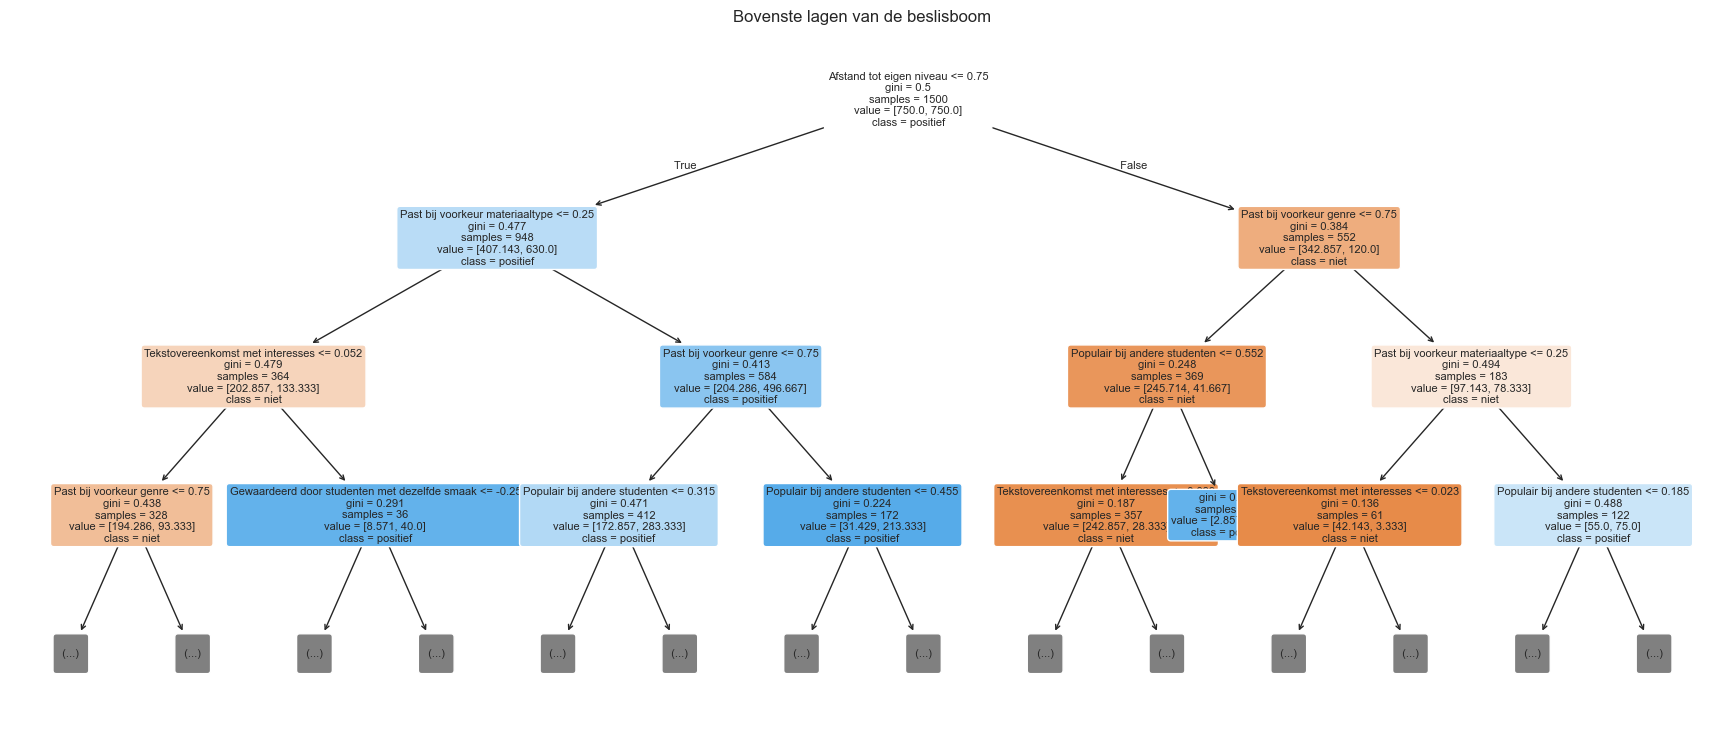

In [5]:
from sklearn.tree import plot_tree

tree = candidates["Beslisboom"]
plt.figure(figsize=(22, 9))
plot_tree(tree, max_depth=3, feature_names=[FEATURE_LABELS[c] for c in FEATURE_COLUMNS], class_names=["niet", "positief"],
          filled=True, rounded=True, fontsize=8)
plt.title("Bovenste lagen van de beslisboom")
plt.savefig(config.FIGURES_DIR / "06_beslisboom.png", dpi=110)
plt.show()

## 4. Wat weegt mee? Feature importance en permutation importance

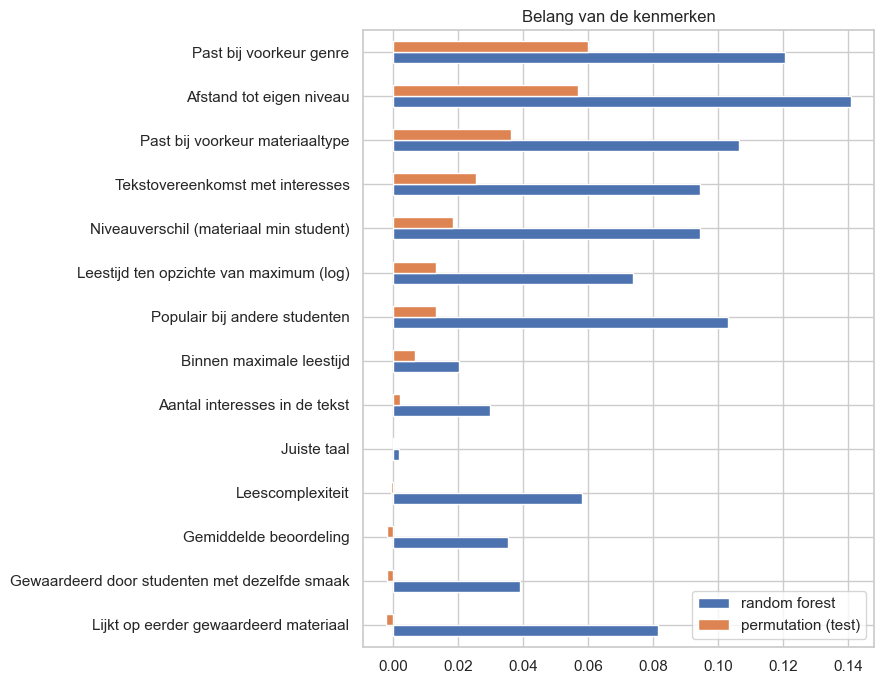

In [6]:
from sklearn.inspection import permutation_importance

forest = candidates["Random forest"]
importance = pd.DataFrame({
    "random forest": pd.Series(forest.feature_importances_, index=FEATURE_COLUMNS),
    "permutation (test)": pd.Series(
        permutation_importance(forest, X_test, y_test, scoring="roc_auc", n_repeats=10, random_state=config.RANDOM_STATE).importances_mean,
        index=FEATURE_COLUMNS),
}).rename(index=FEATURE_LABELS).sort_values("permutation (test)")
importance.plot.barh(figsize=(9, 7), title="Belang van de kenmerken")
plt.tight_layout()
plt.savefig(config.FIGURES_DIR / "06_feature_importance.png", dpi=120)
plt.show()

## 5. Hyperparameters afstemmen
We zoeken de beste instellingen met GridSearchCV, met groepen per student zodat dezelfde student niet in train en validatie zit.

In [7]:
from sklearn.model_selection import GridSearchCV

grid = GridSearchCV(
    RandomForestClassifier(n_estimators=300, class_weight="balanced", random_state=config.RANDOM_STATE, n_jobs=-1),
    param_grid={"max_depth": [4, 8, 12, None], "min_samples_leaf": [1, 5, 15]},
    scoring="roc_auc",
    cv=GroupKFold(5),
)
grid.fit(X_train, y_train, groups=train_frame["student_id"])
print("Beste instellingen:", grid.best_params_, "AUC", round(grid.best_score_, 3))
pd.DataFrame(grid.cv_results_).pivot_table(index="param_max_depth", columns="param_min_samples_leaf", values="mean_test_score").round(3)

Beste instellingen: {'max_depth': 8, 'min_samples_leaf': 1} AUC 0.848


param_min_samples_leaf,1,5,15
param_max_depth,,,
4,0.843,0.842,0.842
8,0.848,0.847,0.845
12,0.844,0.846,0.844


## 6. Kalibratie: klopt de kans?
Als het model 0.7 zegt, wordt het materiaal dan ook ongeveer 70% van de keren positief ontvangen?

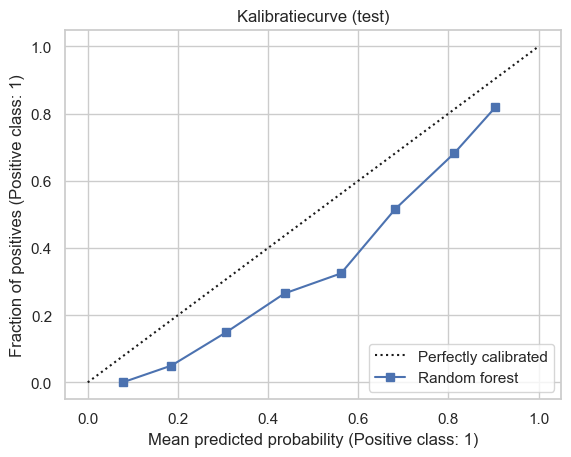

In [8]:
from sklearn.calibration import CalibrationDisplay

CalibrationDisplay.from_estimator(forest, X_test, y_test, n_bins=8, name="Random forest")
plt.title("Kalibratiecurve (test)")
plt.show()

## 7. Als recommender: top 5 uit de hele catalogus
Nu het echte doel: als we de hele catalogus sorteren, staan de materialen die de student later goed vond dan in de top 5? We vergelijken met eenvoudige alternatieven, waaronder de regels die nu in de Fastify app zitten.

In [9]:
from leescoach.evaluation import catalog_coverage, evaluate_rankings, make_scorers

model = HybridRecommender().fit(materials, students, train)
ranking = evaluate_rankings(make_scorers(model, train, students), students, train, test, k=5)
ranking

,precision@5,recall@5,ndcg@5,hitrate@5,auc_test_interacties,auc_per_student
methode,,,,,,
Willekeurig,0.010,0.021,0.017,0.037,0.499,0.484
Populariteit,0.047,0.132,0.121,0.235,0.637,0.649
Regels (huidige app),0.035,0.119,0.070,0.160,0.638,0.615
Content based (TF-IDF),0.017,0.040,0.040,0.086,0.624,0.640
Item KNN,0.010,0.029,0.019,0.049,0.534,0.528
Matrix factorisatie (SVD),0.020,0.072,0.055,0.099,0.595,0.568
Hybride model (Random Forest),0.057,0.184,0.125,0.272,0.825,0.774


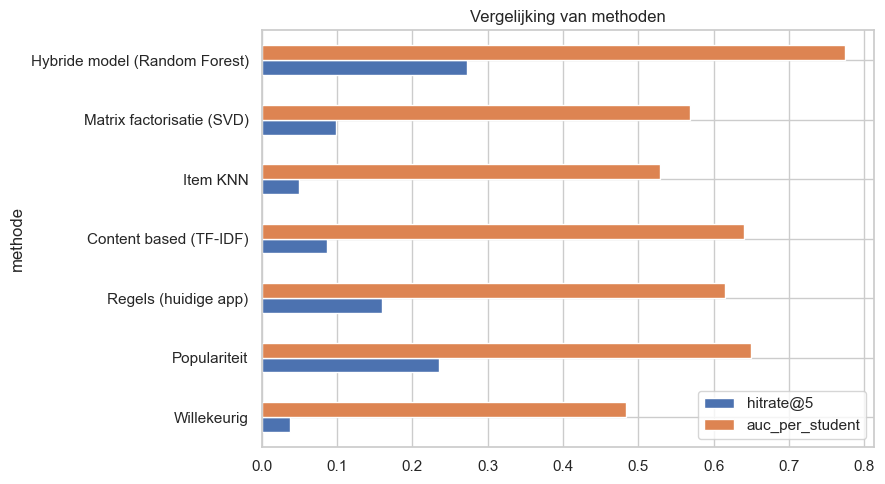

Catalogusdekking: 47% van de catalogus komt in minstens een advies voor


In [10]:
ranking[["hitrate@5", "auc_per_student"]].plot.barh(figsize=(9, 5), title="Vergelijking van methoden")
plt.tight_layout()
plt.savefig(config.FIGURES_DIR / "06_vergelijking_methoden.png", dpi=120)
plt.show()
print(f"Catalogusdekking: {catalog_coverage(model, students, train):.0%} van de catalogus komt in minstens een advies voor")

## 8. Eerlijkheid: werkt het even goed voor elke groep?
We controleren of het model voor elk leesniveau en elke leeftijdsgroep ongeveer even goed werkt. Een groot verschil zou betekenen dat een groep slechter advies krijgt.

In [11]:
groups = test_frame.merge(students[["student_id", "leesniveau", "leeftijdscategorie", "taalniveau"]], on="student_id")
groups["kans"] = forest.predict_proba(groups[FEATURE_COLUMNS])[:, 1]
fairness = []
for column in ["leesniveau", "leeftijdscategorie", "taalniveau"]:
    for value, part in groups.groupby(column):
        if part["positief"].nunique() == 2:
            fairness.append({"groep": column, "waarde": value, "n": len(part), "auc": roc_auc_score(part["positief"], part["kans"])})
pd.DataFrame(fairness).round(3)

,groep,waarde,n,auc
0,leesniveau,2F,274,0.823
1,leesniveau,3F,135,0.824
2,leesniveau,3F+,77,0.828
3,leeftijdscategorie,16-18,183,0.818
4,leeftijdscategorie,19-21,196,0.823
5,leeftijdscategorie,22+,107,0.836
6,taalniveau,A2,59,0.843
7,taalniveau,B1,150,0.826
8,taalniveau,B2,171,0.841
9,taalniveau,C1,106,0.790


## Conclusie

* Het hybride model rangschikt de test interacties duidelijk beter (AUC rond 0.82) dan willekeurig, populariteit, alleen
  tekst, alleen collaborative filtering en de huidige regels in de app (allemaal onder 0.65). Het combineren van signalen
  is dus de meerwaarde van AI hier.
* In de top 5 uit de hele catalogus is het verschil met **populariteit** klein. Populariteit is een sterke en eerlijke
  baseline; het hybride model wint vooral doordat het persoonlijker is (het weet wat te moeilijk of te lang is).
* De belangrijkste signalen zijn het **niveau**, het **genre**, het **materiaaltype**, de **populariteit**, de
  **tekstovereenkomst met interesses** en de **leestijd**.
* De top 5 precisie is laag in absolute zin. Dat komt doordat we per student maar een paar positieve test interacties
  hebben, terwijl er 275 materialen zijn: een student kan ook goede materialen nooit gezien hebben. De AUC per student
  is daarom de eerlijkere maat.
* De AUC is voor alle leesniveaus en leeftijden vergelijkbaar. Voor studenten met taalniveau C1 is hij iets lager:
  houd dat in de gaten als er echte data is.
* De dataset is gesimuleerd: valideer het model met echte studenten (A/B test met de huidige regels) voordat het breed
  ingezet wordt.